# Etapa 7: K-means

Entrada: `data/processed/renda.csv`. Pré-processamento, K-means e métricas de `src/clusters.py`.

Até a etapa 6, todos os modelos eram supervisionados: aprendiam a prever a renda a partir de exemplos com a resposta. O K-means é não supervisionado: recebe só os 10 atributos, sem a renda, e procura grupos de pessoas parecidas entre si. Não há divisão treino/teste; os grupos são formados na base inteira. A renda entra só no fim, para ver se os grupos encontrados têm relação com ela. Raça e sexo ficam fora do agrupamento, como nos modelos anteriores.

1. Pré-processamento e o peso de cada atributo na distância
2. Com e sem log no ganho e na perda de capital
3. Curvas para k de 2 a 10: inércia, silhueta e Davies-Bouldin, nas 10 seeds
4. Estabilidade: ARI entre as seeds, com 10 inicializações e com uma só
5. Escolha do k
6. Perfil dos grupos
7. Comparação com a renda
8. Raça e sexo em cada grupo
9. Os grupos em duas dimensões
10. Tempo
11. Curvas com e sem log
12. Silhueta por grupo
13. As alternativas: k = 5 e k = 8

Todos os tempos são medidos num único núcleo, como nas etapas anteriores.

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import clusters, config

X, renda, sensiveis = clusters.carregar()
Z = clusters.transformar(X, log_capital=True)
print("pessoas:", len(X), "| colunas depois do pré-processamento:", Z.shape[1])
print("k testados:", clusters.KS, "| seeds:", config.SEEDS, "| inicializações por ajuste:", clusters.N_INIT)

pessoas: 30139 | colunas depois do pré-processamento: 80
k testados: [2, 3, 4, 5, 6, 7, 8, 9, 10] | seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | inicializações por ajuste: 10


## 1. Pré-processamento e o peso de cada atributo na distância

O pré-processamento é o da SVM: os 5 numéricos padronizados (média 0, desvio 1) e os 5 de texto em one-hot (75 colunas), 80 colunas no total. A única diferença é o log (`log1p`) no ganho e na perda de capital antes da padronização, discutido na seção 2.

O K-means agrupa pela distância euclidiana ao quadrado, que soma a diferença ao quadrado coluna por coluna. Um numérico padronizado contribui com (diferença em desvios)²; um atributo de texto contribui com 0 quando as duas pessoas têm a mesma categoria e com 2 quando têm categorias diferentes (uma coluna apaga e outra acende).

A tabela mostra quanto cada atributo contribui, em média, para a distância entre duas pessoas sorteadas ao acaso: 2 para cada numérico, e 2 × (chance de as duas pessoas terem categorias diferentes) para cada atributo de texto.

In [2]:
peso = clusters.peso_na_distancia(Z)
print("parte dos categóricos na distância média:",
      f"{peso.loc[peso['tipo'] == 'categórico', 'parte do total (%)'].sum():.1f}%")
peso.round(2)

parte dos categóricos na distância média: 36.6%


,contribuição média,parte do total (%),tipo
idade,2.00,12.68,numérico
anos de estudo,2.00,12.68,numérico
ganho de capital,2.00,12.68,numérico
perda de capital,2.00,12.68,numérico
horas por semana,2.00,12.68,numérico
classe de trabalho,0.88,5.56,categórico
estado civil,1.31,8.33,categórico
ocupação,1.79,11.34,categórico
relacionamento,1.45,9.22,categórico
país de origem,0.34,2.13,categórico


Em média, os 5 numéricos respondem por 63% da distância entre duas pessoas, e os 5 de texto por 37%. O país quase não pesa (2,1%): 91% das pessoas são dos EUA, e duas pessoas sorteadas quase sempre têm o mesmo país. A ocupação, com 14 categorias equilibradas, pesa quase como um numérico.

A média esconde a forma da diferença. Um numérico varia aos poucos; um atributo de texto é tudo ou nada: duas pessoas com ocupações diferentes ficam a 2 de distância ao quadrado, o mesmo que 1,4 desvio padrão de diferença num numérico (18 anos de idade). Esses degraus tendem a marcar as fronteiras entre os grupos.

## 2. Com e sem log no ganho e na perda de capital

O ganho e a perda de capital são zero para a maioria das pessoas e muito altos para poucas. Padronizados sem log, os maiores valores ficam muito longe da média, e o K-means, que soma distâncias ao quadrado, tende a gastar um grupo só com eles. Com o log, os valores grandes são comprimidos (99.999 vira 11,5; 7.688 vira 8,9; 0 continua 0).

A comparação usa k = 4 e a seed 42. Para cada grupo: tamanho, % de pessoas com ganho e com perda de capital, ganho médio e % acima de 50 mil.

In [3]:
tem_ganho, tem_perda = X["capital.gain"] > 0, X["capital.loss"] > 0
print(f"com ganho de capital: {100 * tem_ganho.mean():.1f}% | com perda: {100 * tem_perda.mean():.1f}%",
      f"| ganho de 99.999: {(X['capital.gain'] == 99999).sum()} pessoas")

for log in [False, True]:
    Zl = clusters.transformar(X, log_capital=log)
    gain = Zl["capital.gain"]
    modelo, _ = clusters.ajustar(Zl.values, k=4, seed=config.RANDOM_STATE)
    g = pd.Series(modelo.labels_, index=X.index)
    tabela = pd.DataFrame({
        "pessoas": g.value_counts(),
        "% com ganho": 100 * tem_ganho.groupby(g).mean(),
        "% com perda": 100 * tem_perda.groupby(g).mean(),
        "ganho médio": X["capital.gain"].groupby(g).mean(),
        "% >50K": 100 * renda.groupby(g).mean(),
    }).sort_values("pessoas", ascending=False).rename_axis("grupo")
    print(f"\n{'com' if log else 'sem'} log: ganho padronizado de quem tem zero = {gain[~tem_ganho].iloc[0]:.2f};",
          f"de quem tem 99.999 = {gain.max():.1f} desvios")
    display(tabela.round(1))

com ganho de capital: 8.4% | com perda: 4.7% | ganho de 99.999: 148 pessoas



sem log: ganho padronizado de quem tem zero = -0.15; de quem tem 99.999 = 13.3 desvios


,pessoas,% com ganho,% com perda,ganho médio,% >50K
grupo,,,,,
1,16888,11.3,0.1,928.2,36.7
0,11709,4.1,0.1,210.3,3.7
2,1394,0.0,100.0,0.0,52.7
3,148,100.0,0.0,99999.0,100.0



com log: ganho padronizado de quem tem zero = -0.30; de quem tem 99.999 = 4.4 desvios


,pessoas,% com ganho,% com perda,ganho médio,% >50K
grupo,,,,,
1,15496,0.0,0.0,0.0,31.6
0,10706,0.3,0.0,1.7,2.6
2,2510,100.0,0.0,13115.0,63.5
3,1427,0.0,100.0,0.0,51.6


**Sem log**, as 148 pessoas com ganho de 99.999 (o teto do censo) ficam a 13,3 desvios da média e formam um grupo só delas, todas acima de 50 mil. Outro grupo reúne as 1.394 pessoas com perda de capital.

**Com log**, o grupo das 148 desaparece: o máximo cai para 4,4 desvios. Mas aparece outro efeito. Quem não tem ganho fica em −0,30, e quem tem algum ganho fica perto de +3 desvios: ter ou não ter capital vira o maior degrau da base, maior que qualquer troca de categoria. As 2.510 pessoas com ganho e as 1.427 com perda formam dois grupos próprios, com 63,5% e 51,6% acima de 50 mil.

Ficamos com o log: os grupos do capital são reais e têm sentido (renda alta muito acima da média), enquanto o grupo das 148 é um artefato do teto do censo. A consequência, que pesa na escolha do k, é que dois dos k grupos ficam com os 13% das pessoas que têm capital, e os demais dividem os outros 87%.

## 3. Curvas para k de 2 a 10

Para cada k, o K-means roda com as 10 seeds (0 a 9). Cada seed faz 10 inicializações (`n_init=10`) e fica com a de menor inércia. As três métricas olham só os atributos, nunca a renda:

- **inércia**: soma das distâncias ao quadrado de cada pessoa ao centro do seu grupo. Sempre cai com k; procura-se o cotovelo, a partir do qual cai pouco;
- **silhueta** (de −1 a 1, maior é melhor): para cada pessoa, compara a distância média ao próprio grupo (a) com a distância média ao grupo vizinho mais próximo (b), (b − a) / máx(a, b). Calculada numa amostra fixa de 10 mil pessoas, a mesma em todos os ajustes, porque compara todos os pares;
- **Davies-Bouldin** (menor é melhor): para cada grupo, o pior caso de (espalhamento do grupo + espalhamento do vizinho) / distância entre os centros, na média dos grupos.

Os pontos são a média das 10 seeds, e a faixa, ± um desvio.

In [4]:
curvas, rotulos = clusters.curvas(Z.values)
estab = clusters.estabilidade(rotulos)
curvas_1, rotulos_1 = clusters.curvas(Z.values, n_init=1)
estab_1 = clusters.estabilidade(rotulos_1)

config.RESULTS_DIR.mkdir(exist_ok=True)
pd.concat([curvas, curvas_1]).to_csv(config.RESULTS_DIR / "clusters_curvas.csv", index=False)
pd.concat([estab.assign(n_init=clusters.N_INIT), estab_1.assign(n_init=1)]).to_csv(
    config.RESULTS_DIR / "clusters_estabilidade.csv", index=False)

resumo = clusters.resumir_curvas(curvas, estab)
resumo.round(3)

,inércia (média),inércia (desvio),silhueta (média),silhueta (desvio),Davies-Bouldin (média),Davies-Bouldin (desvio),tempo (s) (média),tempo (s) (desvio),ARI médio,ARI mínimo
k,,,,,,,,,,
2,206442.038,171.930,0.314,0.030,1.274,0.093,0.204,0.030,0.789,-0.055
3,178031.434,1531.148,0.205,0.093,1.660,0.342,0.374,0.084,0.589,0.127
4,153329.453,4274.493,0.175,0.014,1.680,0.124,0.442,0.053,0.858,0.602
5,138246.969,0.727,0.169,0.000,1.717,0.001,1.182,0.180,0.977,0.953
6,129755.420,0.094,0.165,0.000,1.707,0.000,0.976,0.078,0.995,0.977
7,123438.154,94.747,0.154,0.001,1.710,0.018,1.201,0.105,0.926,0.800
8,118018.830,0.027,0.152,0.000,1.667,0.000,0.925,0.079,0.997,0.994
9,113503.133,171.952,0.157,0.002,1.688,0.032,1.127,0.201,0.786,0.633
10,109249.317,130.513,0.161,0.000,1.666,0.010,1.122,0.126,0.904,0.736


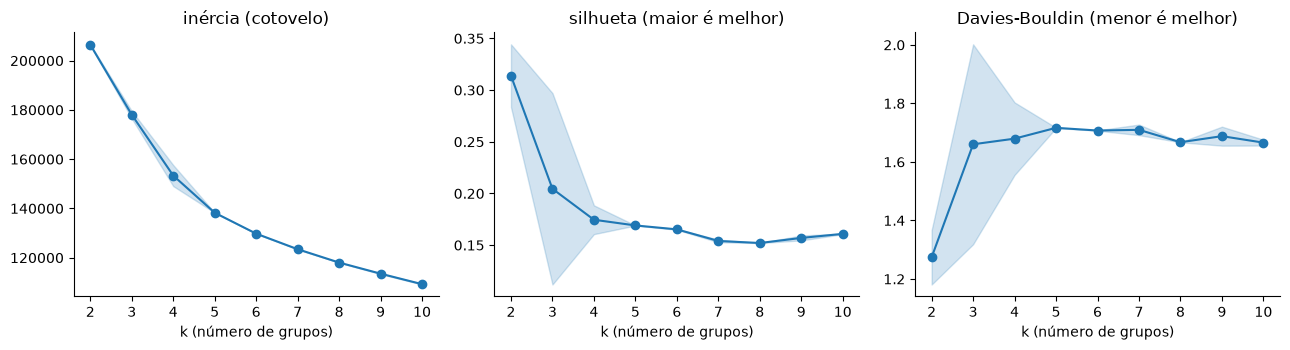

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, metrica, melhor in zip(eixos, ["inércia", "silhueta", "Davies-Bouldin"],
                               ["cotovelo", "maior é melhor", "menor é melhor"]):
    media, desvio = resumo[f"{metrica} (média)"], resumo[f"{metrica} (desvio)"]
    ax.plot(resumo.index, media, marker="o", color="tab:blue")
    ax.fill_between(resumo.index, media - desvio, media + desvio, color="tab:blue", alpha=0.2)
    ax.set_title(f"{metrica} ({melhor})")
    ax.set_xlabel("k (número de grupos)")
    ax.set_xticks(clusters.KS)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

- **Inércia**: cai sempre, como esperado. As quedas de um k para o seguinte são de 28 mil (2→3), 25 mil (3→4), 15 mil (4→5) e 8,5 mil (5→6); a partir daí ficam entre 4 e 6 mil. O cotovelo fica entre 5 e 6.
- **Silhueta**: a maior é a de k = 2 (0,31). De k = 4 em diante fica plana, entre 0,15 e 0,17. Valores tão baixos (acima de 0,5 indicaria grupos bem separados) mostram que a base não tem grupos nítidos: os grupos são regiões de uma nuvem contínua de pessoas.
- **Davies-Bouldin**: também prefere k = 2 (1,27) e fica plano, em torno de 1,7, a partir de k = 3.
- **Faixas**: em k = 2, 3 e 4 as seeds chegam a soluções diferentes, e as faixas são largas; de k = 5 em diante quase somem (a seção 4 mostra que k = 7 e 9 ainda variam um pouco).

## 4. Estabilidade

Para cada k, as 10 seeds geram 10 partições, comparadas duas a duas pelo ARI (*Adjusted Rand Index*, 45 pares). O ARI mede se duas partições põem as mesmas pessoas juntas, sem importar o número de cada grupo: 1 quando são idênticas, perto de 0 quando a concordância é a do acaso. Um k em que as seeds concordam indica grupos que estão nos dados; um k instável indica que o algoritmo está dividindo uma região sem fronteira clara.

A comparação com uma só inicialização por seed (`n_init=1`) mostra por que as 10 inicializações existem.

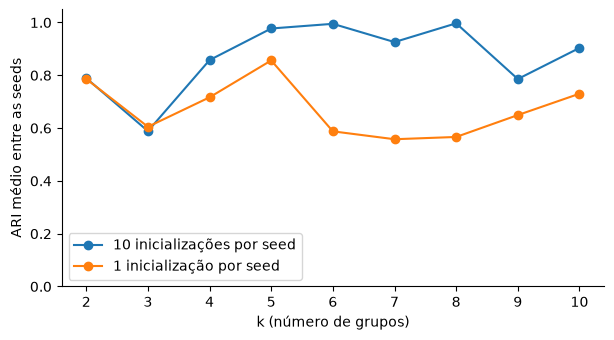

k = 2, tamanho do grupo menor em cada seed: {0: 2533, 1: 1427, 2: 2533, 3: 2533, 4: 2533, 5: 2533, 6: 2533, 7: 2533, 8: 2533, 9: 2533}


,ARI médio (n_init=10),ARI mínimo (n_init=10),ARI médio (n_init=1),ARI mínimo (n_init=1),inércia: piora com n_init=1 (%)
k,,,,,
2,0.789,-0.055,0.786,-0.009,0.731
3,0.589,0.127,0.605,0.113,3.248
4,0.858,0.602,0.717,0.515,6.091
5,0.977,0.953,0.856,0.392,1.723
6,0.995,0.977,0.588,0.321,2.998
7,0.926,0.800,0.558,0.320,4.125
8,0.997,0.994,0.566,0.357,2.155
9,0.786,0.633,0.649,0.404,1.826
10,0.904,0.736,0.730,0.540,1.900


In [6]:
comparacao = pd.concat([
    estab.set_index("k")[["ARI médio", "ARI mínimo"]].add_suffix(" (n_init=10)"),
    estab_1.set_index("k")[["ARI médio", "ARI mínimo"]].add_suffix(" (n_init=1)"),
], axis=1)
comparacao["inércia: piora com n_init=1 (%)"] = 100 * (
    curvas_1.groupby("k")["inércia"].mean() / curvas.groupby("k")["inércia"].mean() - 1)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(estab["k"], estab["ARI médio"], marker="o", color="tab:blue", label="10 inicializações por seed")
ax.plot(estab_1["k"], estab_1["ARI médio"], marker="o", color="tab:orange", label="1 inicialização por seed")
ax.set_xlabel("k (número de grupos)")
ax.set_ylabel("ARI médio entre as seeds")
ax.set_xticks(clusters.KS)
ax.set_ylim(0, 1.05)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

menor_k2 = {s: int(np.bincount(rotulos[2][s]).min()) for s in config.SEEDS}
print("k = 2, tamanho do grupo menor em cada seed:", menor_k2)
comparacao.round(3)

Com 10 inicializações, as partições de k = 5, 6 e 8 são praticamente idênticas nas 10 seeds (ARI médio de 0,977, 0,995 e 0,997). k = 3 (0,59) e k = 9 (0,79) são instáveis: o algoritmo divide uma região sem fronteira clara, e cada seed divide de um jeito.

Em k = 2, o ARI mínimo é negativo: há duas soluções quase com a mesma inércia. Em 9 seeds, o grupo pequeno é o das pessoas com ganho de capital (2.533); na seed 1, o das pessoas com perda (1.427).

Com uma só inicialização, a estabilidade despenca (em k = 6, de 0,995 para 0,59) e a inércia piora de 1% a 6%: cada sorteio para num mínimo local diferente. As 10 inicializações custam 10 vezes mais tempo e compram a mesma resposta em todas as seeds.

## 5. Escolha do k

Nenhuma métrica sozinha decide; as quatro evidências apontam para lados diferentes:

- **silhueta e Davies-Bouldin** preferem k = 2, mas esse k só separa quem tem ganho de capital (ou, numa seed, quem tem perda) do resto. É a fronteira mais nítida da base, e diz pouco sobre os outros 92%;
- **o cotovelo** fica entre 5 e 6: a queda da inércia cai quase à metade depois de k = 5;
- **a estabilidade** é quase perfeita em k = 5, 6 e 8 (ARI médio de 0,98 ou mais) e ruim em k = 3 e 9;
- **a leitura dos grupos**: em qualquer k a partir de 4, dois grupos são do capital (ganho e perda), e os demais dividem os 87% sem capital. Com k = 6, sobram quatro grupos para essas pessoas, com perfis distintos; com k = 5, três; com k = 8, seis, alguns difíceis de distinguir.

Escolhemos **k = 6**: está no cotovelo, é o mais estável até k = 7 (ARI médio de 0,995) e dá quatro perfis claros para quem não tem capital.

In [7]:
K = clusters.K_ESCOLHIDO
resumo.loc[[4, 5, 6, 7, 8], ["inércia (média)", "silhueta (média)", "Davies-Bouldin (média)", "ARI médio", "ARI mínimo"]].round(3)

,inércia (média),silhueta (média),Davies-Bouldin (média),ARI médio,ARI mínimo
k,,,,,
4,153329.453,0.175,1.680,0.858,0.602
5,138246.969,0.169,1.717,0.977,0.953
6,129755.420,0.165,1.707,0.995,0.977
7,123438.154,0.154,1.710,0.926,0.800
8,118018.830,0.152,1.667,0.997,0.994


## 6. Perfil dos grupos

A partição descrita daqui em diante é a da seed 42, fora das seeds 0 a 9 usadas na estabilidade. O número que o K-means dá a cada grupo é arbitrário; para facilitar a leitura, os grupos foram renumerados de 1 a 6, do menor para o maior % acima de 50 mil. A renda só ordena os nomes; não influencia a formação dos grupos.

O perfil mostra, para cada grupo, a média dos numéricos na escala original e a categoria mais comum de cada atributo de texto, com a sua proporção dentro do grupo. A última coluna é a base inteira, para referência.

In [8]:
modelo, tempo_ajuste = clusters.ajustar(Z.values, K, seed=config.RANDOM_STATE)
grupo = clusters.ordenar_por_renda(modelo.labels_, renda)
silhueta, db = clusters.metricas_internas(Z.values, grupo)
print(f"k = {K}, seed {config.RANDOM_STATE}: inércia {modelo.inertia_:,.0f} | silhueta {silhueta:.3f}",
      f"| Davies-Bouldin {db:.3f} | {modelo.n_iter_} iterações | {tempo_ajuste:.2f} s")
print("ARI contra as partições das seeds 0 a 9:",
      np.round([clusters.adjusted_rand_score(grupo, rotulos[K][s]) for s in config.SEEDS], 3))

perfil = clusters.perfil(X, grupo)
perfil.loc["% com ganho de capital"] = [100 * (X.loc[grupo == g, "capital.gain"] > 0).mean() for g in range(1, K + 1)] + [100 * (X["capital.gain"] > 0).mean()]
perfil.loc["% com perda de capital"] = [100 * (X.loc[grupo == g, "capital.loss"] > 0).mean() for g in range(1, K + 1)] + [100 * (X["capital.loss"] > 0).mean()]
perfil.map(lambda v: round(v, 1) if isinstance(v, float) else v)

k = 6, seed 42: inércia 129,755 | silhueta 0.165 | Davies-Bouldin 1.707 | 13 iterações | 0.82 s
ARI contra as partições das seeds 0 a 9: [0.999 0.999 0.999 0.999 0.977 0.999 0.999 0.999 0.999 0.998]


,1,2,3,4,5,6,toda a base
pessoas,8439,5443,6538,5791,1427,2501,30139
idade,25.7,53.4,37.6,40.9,41.6,43.7,38.4
anos de estudo,9.4,8.5,9.0,13.3,11.0,11.2,10.1
ganho de capital,2.4,2.1,0.0,0.0,0.0,13156.7,1092.8
perda de capital,0.0,0.0,0.0,0.0,1867.9,0.0,88.4
horas por semana,34.4,36.3,47.6,45.1,43.5,44.3,40.9
classe de trabalho,Private (88%),Private (71%),Private (74%),Private (60%),Private (67%),Private (67%),Private (74%)
estado civil,Never-married (82%),Married-civ-spouse (37%),Married-civ-spouse (90%),Married-civ-spouse (57%),Married-civ-spouse (64%),Married-civ-spouse (68%),Married-civ-spouse (47%)
ocupação,Other-service (20%),Adm-clerical (18%),Craft-repair (26%),Prof-specialty (40%),Exec-managerial (20%),Prof-specialty (22%),Prof-specialty (13%)
relacionamento,Own-child (45%),Not-in-family (34%),Husband (84%),Husband (50%),Husband (57%),Husband (60%),Husband (41%)


A partição da seed 42 concorda com as das seeds 0 a 9 (ARI de 0,977 a 0,999): é a mesma partição das outras seeds. Os seis grupos, nomeados pelo perfil:

| Grupo | Pessoas | Perfil |
|---|---|---|
| 1. Jovens solteiros | 8.439 | 26 anos, 82% nunca casados, 45% moram com os pais, 34 h por semana |
| 2. Mais velhos sem cônjuge | 5.443 | 53 anos, divorciados (34%) e viúvos (11%), 8,5 anos de estudo |
| 3. Casados em ofícios manuais | 6.538 | 38 anos, 90% casados, 9 anos de estudo, 48 h por semana |
| 4. Profissionais com muito estudo | 5.791 | 41 anos, 13,3 anos de estudo, especialistas e gerentes (65%) |
| 5. Com perda de capital | 1.427 | todos com perda de capital (média de 1.868 dólares) |
| 6. Com ganho de capital | 2.501 | todos com ganho de capital (média de 13.157 dólares) |

Os grupos 1 a 4, sem capital, se separam pela fase da vida (idade, estado civil, relacionamento) e pelo estudo e tipo de trabalho. Os grupos 5 e 6 são parecidos entre si nos outros atributos (cerca de 42 anos, 11 anos de estudo, dois terços casados, muitos gerentes e especialistas): o que os separa do resto e um do outro é o capital.

In [9]:
for atributo in ["marital.status", "relationship", "occupation"]:
    tabela = clusters.proporcoes(X, grupo, atributo)
    display(tabela.loc[tabela.max(axis=1) >= 10].round(0))

grupo,1,2,3,4,5,6
estado civil,,,,,,
Divorced,9.0,34.0,4.0,15.0,11.0,11.0
Married-civ-spouse,3.0,37.0,90.0,57.0,64.0,68.0
Never-married,82.0,9.0,4.0,23.0,20.0,16.0
Widowed,0.0,11.0,0.0,1.0,2.0,2.0


grupo,1,2,3,4,5,6
relacionamento,,,,,,
Husband,1.0,31.0,84.0,50.0,57.0,60.0
Not-in-family,35.0,34.0,6.0,30.0,22.0,20.0
Own-child,45.0,3.0,1.0,4.0,7.0,4.0
Unmarried,13.0,23.0,2.0,9.0,6.0,7.0


grupo,1,2,3,4,5,6
ocupação,,,,,,
Adm-clerical,19.0,18.0,6.0,7.0,9.0,9.0
Craft-repair,10.0,13.0,26.0,4.0,13.0,12.0
Exec-managerial,5.0,10.0,11.0,25.0,20.0,22.0
Machine-op-inspct,7.0,9.0,10.0,1.0,4.0,5.0
Other-service,20.0,15.0,6.0,2.0,4.0,3.0
Prof-specialty,6.0,5.0,3.0,40.0,20.0,22.0
Sales,14.0,10.0,10.0,12.0,13.0,13.0
Transport-moving,3.0,6.0,11.0,1.0,5.0,4.0


As proporções confirmam os perfis: o grupo 1 concentra os nunca casados e quem mora com os pais; o grupo 2, os divorciados, viúvos e quem cria filhos sem cônjuge (*Unmarried*); o grupo 3 é quase todo de maridos (84%) em ocupações manuais (reparos, transporte, operação de máquinas); o grupo 4 tem 40% de especialistas e 25% de gerentes.

## 7. Comparação com a renda

Só agora a renda entra. Para cada grupo, o % de pessoas acima de 50 mil; para a partição inteira, a pureza (se cada grupo respondesse a sua renda mais comum, quantas pessoas acertariam) e o ARI contra a renda. Como 75,1% ganham até 50 mil, uma partição sem relação nenhuma com a renda já tem pureza de 75,1%.

pureza: 77.5% | chute (classe majoritária): 75.1% | ARI contra a renda: 0.091


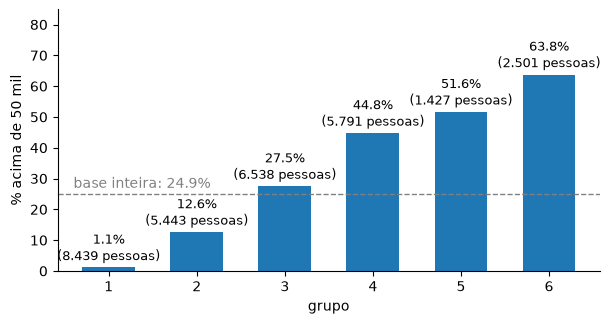

,pessoas,% das pessoas,% >50K
grupo,,,
1,8439,28.0,1.1
2,5443,18.1,12.6
3,6538,21.7,27.5
4,5791,19.2,44.8
5,1427,4.7,51.6
6,2501,8.3,63.8


In [10]:
por_grupo, contra_renda = clusters.comparar_renda(grupo, renda)
print(f"pureza: {100 * contra_renda['pureza']:.1f}% | chute (classe majoritária): {100 * contra_renda['chute (classe majoritária)']:.1f}%",
      f"| ARI contra a renda: {contra_renda['ARI contra a renda']:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(por_grupo.index.astype(str), por_grupo["% >50K"], color="tab:blue", width=0.6)
ax.axhline(100 * renda.mean(), color="gray", linestyle="--", linewidth=1)
ax.text(-0.4, 100 * renda.mean() + 1, f"base inteira: {100 * renda.mean():.1f}%", va="bottom", ha="left", color="gray")
for x, (v, n) in enumerate(zip(por_grupo["% >50K"], por_grupo["pessoas"])):
    ax.text(x, v + 1, f"{v:.1f}%\n({n:,} pessoas)".replace(",", "."), ha="center", va="bottom", fontsize=9)
ax.set_xlabel("grupo")
ax.set_ylabel("% acima de 50 mil")
ax.set_ylim(0, 85)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

numericos = perfil.loc[[config.NOMES[c] for c in config.NUMERICAS] + ["% com ganho de capital", "% com perda de capital"],
                       list(range(1, K + 1))].T.astype(float)
grupos_csv = por_grupo.join(numericos)
for c in config.CATEGORICAS:
    grupos_csv[config.NOMES[c]] = perfil.loc[config.NOMES[c], list(range(1, K + 1))]
grupos_csv.to_csv(config.RESULTS_DIR / "clusters_grupos.csv")
pd.DataFrame([{"k": K, "seed": config.RANDOM_STATE, "inércia": modelo.inertia_, "silhueta": silhueta,
               "Davies-Bouldin": db, "iterações": modelo.n_iter_, "tempo (s)": tempo_ajuste, **contra_renda}]
             ).to_csv(config.RESULTS_DIR / "clusters_kmeans.csv", index=False)
por_grupo.round(1)

O K-means não viu a renda, e mesmo assim os grupos se ordenam por ela: de 1,1% acima de 50 mil nos jovens solteiros a 44,8% nos profissionais com muito estudo e 63,8% em quem tem ganho de capital. Os atributos que formam os grupos (idade, estudo, estado civil, ocupação, capital) são os mesmos que explicam a renda.

Como partição da renda, porém, os grupos são fracos: a pureza é de 77,5%, só 2,4 pontos acima do chute de 75,1%, e o ARI contra a renda é de 0,09. Só dois grupos (5 e 6) têm maioria acima de 50 mil, e nenhum grupo é puro. Os grupos descrevem perfis de pessoas, e a renda varia muito dentro de cada perfil: o K-means não substitui um classificador, que acerta 85%.

## 8. Raça e sexo em cada grupo

Raça e sexo não entraram no agrupamento. Esta seção mostra como eles se distribuem nos grupos formados pelos outros atributos; serve só ao relatório (por decisão do grupo, raça e sexo ficam fora dos slides).

In [11]:
sexo = clusters.proporcoes(sensiveis, grupo, "sex")
raca = clusters.proporcoes(sensiveis, grupo, "race")
base = pd.concat([sensiveis["sex"].value_counts(normalize=True), sensiveis["race"].value_counts(normalize=True)]) * 100
tabela = pd.concat([sexo, raca])
tabela["toda a base"] = base
tabela.round(1)

grupo,1,2,3,4,5,6,toda a base
Female,47.7,48.3,8.3,29.2,23.6,21.8,32.4
Male,52.3,51.7,91.7,70.8,76.4,78.2,67.6
Amer-Indian-Eskimo,1.1,1.0,1.1,0.5,0.4,0.9,0.9
Asian-Pac-Islander,3.1,2.3,1.9,4.7,3.1,2.8,3.0
Black,12.8,13.4,6.6,5.7,6.2,6.4,9.3
Other,1.1,0.6,0.9,0.5,0.5,0.4,0.8
White,81.9,82.7,89.5,88.6,89.8,89.4,86.0


Mesmo sem raça e sexo no agrupamento, eles se distribuem de forma desigual. O grupo 3 é 92% masculino, porque o relacionamento "marido" (84% do grupo) indica o sexo quase sem exceção. Os grupos 1 e 2, os de menor renda, têm 48% de mulheres (32% na base) e a maior proporção de pessoas negras (13%, contra 9% na base). Outros atributos, como estado civil e relacionamento, carregam essa informação, e os grupos a refletem.

## 9. Os grupos em duas dimensões

As 80 colunas não cabem num gráfico. A análise de componentes principais (PCA) projeta as pessoas nas duas direções em que a base mais varia. A projeção serve só para desenhar: o K-means agrupou nas 80 colunas, e grupos que se sobrepõem no desenho podem estar separados nas outras direções. Cada ponto é uma pessoa (amostra de 5 mil, para o desenho não virar uma mancha), e os × são os centros dos grupos.

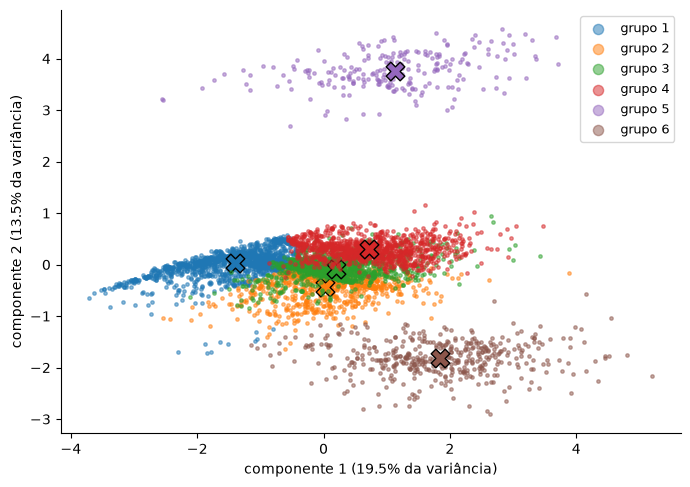

as duas componentes explicam 32.9% da variância das 80 colunas


In [12]:
coords, variancia = clusters.pca_2d(Z)
centros = pd.DataFrame(coords).groupby(grupo).mean().values
amostra = np.random.default_rng(config.RANDOM_STATE).choice(len(Z), 5000, replace=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
cores = plt.cm.tab10.colors
for g in range(1, K + 1):
    m = amostra[grupo[amostra] == g]
    ax.scatter(coords[m, 0], coords[m, 1], s=6, alpha=0.5, color=cores[g - 1], label=f"grupo {g}")
    ax.scatter(*centros[g - 1], marker="X", s=180, color=cores[g - 1], edgecolor="black", linewidth=1)
ax.set_xlabel(f"componente 1 ({100 * variancia[0]:.1f}% da variância)")
ax.set_ylabel(f"componente 2 ({100 * variancia[1]:.1f}% da variância)")
ax.legend(markerscale=3, loc="best", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"as duas componentes explicam {100 * variancia.sum():.1f}% da variância das 80 colunas")

As duas componentes explicam só 33% da variância, de modo que o desenho é uma visão parcial. Mesmo assim, ele mostra o que as métricas indicaram: os grupos do capital (5 e 6) ficam bem separados, cada um numa faixa própria da componente 2, e os grupos 1 a 4 se sobrepõem numa nuvem contínua, ordenados da esquerda (jovens solteiros) para a direita (profissionais). É a explicação da silhueta baixa.

## 10. Tempo

O K-means custa n × k × colunas × iterações por inicialização: cresce linearmente com o número de pessoas. Tempos num único núcleo, nas 30.139 pessoas, com 10 inicializações.

In [13]:
tempos = curvas.groupby("k").agg(tempo_mediano=("tempo (s)", "median"), iteracoes_medias=("iterações", "mean"))
svm_rbf = pd.read_csv(config.RESULTS_DIR / "svm.csv").query("modelo == 'SVM RBF'")
print(f"k = {K}: {tempos.loc[K, 'tempo_mediano']:.2f} s por ajuste (mediana das 10 seeds)")
print(f"para comparação, o treino da SVM RBF nas 24.111 pessoas do treino: {svm_rbf['tempo de treino (s)'].median():.0f} s (mediana)")
tempos.round(2)

k = 6: 0.95 s por ajuste (mediana das 10 seeds)
para comparação, o treino da SVM RBF nas 24.111 pessoas do treino: 6 s (mediana)


,tempo_mediano,iteracoes_medias
k,,
2,0.20,3.6
3,0.33,11.3
4,0.46,16.2
5,1.26,30.7
6,0.95,46.0
7,1.22,36.5
8,0.90,42.1
9,1.07,35.6
10,1.10,51.0


Um ajuste com k = 6 e 10 inicializações leva menos de 1 segundo nas 30 mil pessoas, e o estudo inteiro (180 ajustes: 9 valores de k × 10 seeds, com 10 inicializações e com uma) leva cerca de 4 minutos. O custo cresce linearmente com o número de pessoas, ao contrário da SVM com kernel, cujo treino cresce com o quadrado. O número de iterações aumenta com k, mas fica em dezenas.

## 11. Curvas com e sem log

A seção 2 comparou os dois pré-processamentos só em k = 4. Aqui, as métricas internas para todo k de 2 a 10, na seed 42, com e sem log no capital, e o tamanho do menor grupo de cada partição.

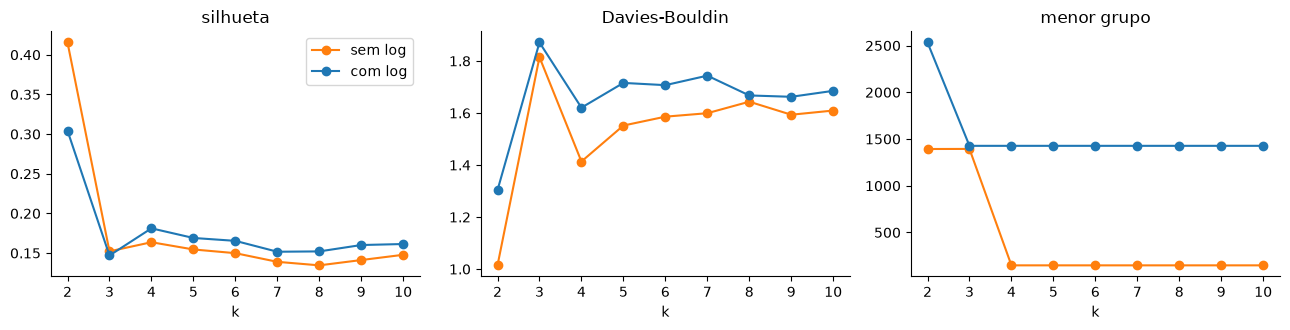

silhueta        Davies-Bouldin        menor grupo        
log    False  True           False  True        False   True 
k                                                            
2      0.415  0.304          1.014  1.303      1393.0  2533.0
3      0.152  0.147          1.815  1.871      1394.0  1427.0
4      0.164  0.181          1.414  1.620       148.0  1427.0
5      0.155  0.169          1.552  1.716       148.0  1427.0
6      0.150  0.165          1.586  1.707       148.0  1427.0
7      0.139  0.152          1.599  1.744       148.0  1427.0
8      0.134  0.152          1.643  1.667       148.0  1427.0
9      0.141  0.160          1.593  1.662       148.0  1427.0
10     0.148  0.161          1.609  1.685       148.0  1427.0

In [14]:
log_curvas = pd.concat([clusters.curvas_uma_seed(clusters.transformar(X, log_capital=log).values).assign(log=log)
                        for log in [False, True]])
log_curvas.to_csv(config.RESULTS_DIR / "clusters_log_curvas.csv", index=False)

fig, eixos = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, metrica in zip(eixos, ["silhueta", "Davies-Bouldin", "menor grupo"]):
    for log, cor, rotulo in [(False, "tab:orange", "sem log"), (True, "tab:blue", "com log")]:
        parte = log_curvas[log_curvas["log"] == log]
        ax.plot(parte["k"], parte[metrica], marker="o", color=cor, label=rotulo)
    ax.set_title(metrica)
    ax.set_xlabel("k")
    ax.set_xticks(clusters.KS)
    ax.spines[["top", "right"]].set_visible(False)
eixos[0].legend()
plt.tight_layout()
plt.show()
log_curvas.pivot(index="k", columns="log", values=["silhueta", "Davies-Bouldin", "menor grupo"]).round(3)

Sem log, o grupo das 148 pessoas com ganho de 99.999 aparece em todo k de 4 em diante (o menor grupo tem sempre 148 pessoas), e a silhueta fica abaixo da versão com log nesses k. A exceção é k = 2, em que a versão sem log tem silhueta maior (0,42), porque separa só as 1.393 pessoas com perda de capital. Com log, o menor grupo passa a ser o das 1.427 pessoas com perda, de k = 3 em diante: o log troca um grupo artificial por um grupo real.

## 12. Silhueta por grupo

A silhueta média (seção 3) resume a partição num número. Calculada pessoa a pessoa, na mesma amostra fixa de 10 mil pessoas, ela mostra quais grupos são compactos e separados e quais se misturam com os vizinhos. Uma silhueta negativa indica uma pessoa mais perto, em média, do grupo vizinho que do próprio.

silhueta média da amostra: 0.165


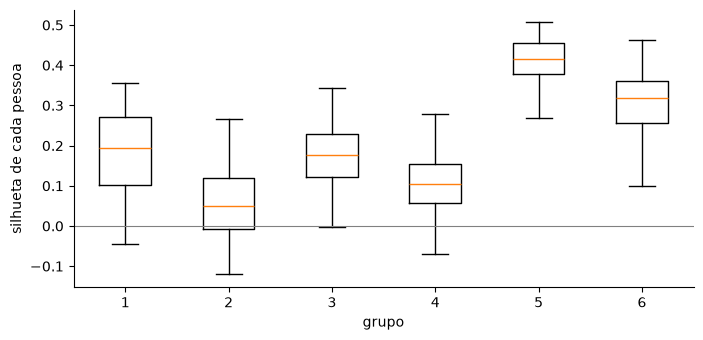

,pessoas na amostra,média,1º quartil,mediana,3º quartil,% negativa
grupo,,,,,,
1,2770,0.189,0.103,0.194,0.272,0.903
2,1806,0.058,-0.009,0.049,0.119,28.295
3,2193,0.174,0.122,0.177,0.230,0.182
4,1919,0.105,0.057,0.104,0.154,7.400
5,465,0.404,0.379,0.417,0.454,0.000
6,847,0.301,0.256,0.318,0.361,0.118


In [15]:
sil_grupos, sil_pessoas, sil_rotulos = clusters.silhueta_por_grupo(Z.values, grupo)
sil_grupos.to_csv(config.RESULTS_DIR / "clusters_silhueta_grupos.csv")
print(f"silhueta média da amostra: {sil_pessoas.mean():.3f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.boxplot([sil_pessoas[sil_rotulos == g] for g in range(1, K + 1)], tick_labels=[str(g) for g in range(1, K + 1)],
           showfliers=False)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("grupo")
ax.set_ylabel("silhueta de cada pessoa")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
sil_grupos.round(3)

Os grupos do capital são os mais bem definidos: silhueta média de 0,40 (perda) e 0,30 (ganho), sem quase nenhuma pessoa com silhueta negativa. Entre os grupos sem capital, os jovens solteiros (0,19) e os casados em ofícios manuais (0,17) são os mais coesos. O grupo 2, dos mais velhos sem cônjuge, é o mais difuso: silhueta média de 0,06, e 28% das suas pessoas estão mais perto, em média, de outro grupo. É um grupo de ``sobra'', de quem não se encaixa nos perfis mais nítidos, e o primeiro a mudar com outro k.

## 13. As alternativas: k = 5 e k = 8

Os perfis que a escolha deixou de fora, na seed 42, com os grupos ordenados pelo % acima de 50 mil, como em k = 6.

In [16]:
alternativas = []
for k in [5, 8]:
    m, _ = clusters.ajustar(Z.values, k, seed=config.RANDOM_STATE)
    rot = clusters.ordenar_por_renda(m.labels_, renda)
    alternativas.append(clusters.resumo_grupos(X, rot, renda).assign(k=k))
alternativas = pd.concat(alternativas).reset_index().set_index(["k", "grupo"])
alternativas.to_csv(config.RESULTS_DIR / "clusters_alternativas.csv")
alternativas.round(1)

pessoas  idade  anos de estudo  horas por semana  % casados  \
k grupo                                                                
5 1         9282   25.9             9.6              34.9        7.4   
  2         9313   47.6             8.5              38.9       61.3   
  3         7608   40.2            12.3              49.3       66.3   
  4         1427   41.6            11.0              43.5       63.6   
  5         2509   43.8            11.1              44.2       68.1   
8 1         2551   22.9             9.2              20.3        6.0   
  2         7403   28.5             9.8              41.1        0.9   
  3         4479   55.2             8.2              36.4       37.0   
  4         5344   37.5             9.0              41.9       99.9   
  5         1881   40.4            10.3              66.3       65.6   
  6         4570   43.2            13.4              42.4       65.7   
  7         1427   41.6            11.0              43.5       63.6   
  8         2484   43.7            11.2              44.2       68.4   

         % nunca casados  % com ganho  % com perda ocupação mais comum  \
k grupo                                                                  
5 1                 79.0          0.3          0.0       Other-service   
  2                  5.5          0.0          0.0        Craft-repair   
  3                 15.6          0.0          0.0      Prof-specialty   
  4                 20.0          0.0        100.0     Exec-managerial   
  5                 15.9        100.0          0.0      Prof-specialty   
8 1                 86.8          1.2          0.0       Other-service   
  2                 74.7          0.1          0.0        Adm-clerical   
  3                  8.7          0.2          0.0        Adm-clerical   
  4                  0.0          0.0          0.0        Craft-repair   
  5                 15.7          0.5          0.0     Exec-managerial   
  6                 13.4          0.0          0.0      Prof-specialty   
  7                 20.0          0.0        100.0     Exec-managerial   
  8                 15.6        100.0          0.0      Prof-specialty   

         % da ocupação  % >50K  
k grupo                         
5 1               19.0     1.8  
  2               21.3    18.7  
  3               28.8    42.9  
  4               20.3    51.6  
  5               21.5    63.6  
8 1               32.3     1.1  
  2               19.1     2.3  
  3               17.5    11.6  
  4               28.8    28.7  
  5               19.6    33.5  
  6               41.8    50.2  
  7               20.3    51.6  
  8               21.6    64.1

Com k = 5, os grupos sem capital são três: jovens solteiros, casados com pouco estudo (que junta os grupos 2 e 3 de k = 6) e casados com muito estudo. Com k = 8, os jovens se dividem pelas horas (22 anos e 20 horas por semana; 28 anos e 41 horas), surge um grupo de quem trabalha 66 horas por semana, e os casados se dividem entre ofícios manuais (quase 100% casados) e profissionais com muito estudo; os mais velhos sem cônjuge continuam num grupo próprio, agora com 55 anos em média. Os dois grupos do capital ficam iguais nos três k. O k = 6 é o menor k que separa os mais velhos sem cônjuge dos casados.